In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
DATA_PATH = Path("../data/processed/cleaned_car_data.csv")

df = pd.read_csv(DATA_PATH)

X = df.drop("Selling_Price", axis=1)
y = df["Selling_Price"]

print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(df.head())

Dataset shape: (299, 9)
Features shape: (299, 8)
Target shape: (299,)
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  


In [3]:
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Numerical features: ['Year', 'Present_Price', 'Kms_Driven', 'Owner']
Categorical features: ['Car_Name', 'Fuel_Type', 'Seller_Type', 'Transmission']
X_train: (239, 8)
X_test: (60, 8)


In [4]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("First 10 predicted prices:")
print(y_pred_linear[:10])

First 10 actual prices:
[8.99 8.35 0.45 7.45 5.25 5.25 5.85 1.15 9.25 0.38]
First 10 predicted prices:
[ 8.11376614  7.6731601   1.41381792  6.75357577  9.83446517  5.0408729
  8.06200749  2.35320337  8.71775116 -1.46946903]


In [5]:
mae = mean_absolute_error(y_test, y_pred_linear)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Linear Regression Results
MAE: 1.411
RMSE: 2.429
R2 Score: 0.771


In [6]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("MAE:", round(mae_tree, 3))
print("RMSE:", round(rmse_tree, 3))
print("R2 Score:", round(r2_tree, 3))


Decision Tree Results
MAE: 1.337
RMSE: 2.968
R2 Score: 0.658


In [7]:
forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(n_estimators=200, random_state=42))
    ]
)

forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)

mae_forest = mean_absolute_error(y_test, y_pred_forest)
rmse_forest = np.sqrt(mean_squared_error(y_test, y_pred_forest))
r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Results")
print("MAE:", round(mae_forest, 3))
print("RMSE:", round(rmse_forest, 3))
print("R2 Score:", round(r2_forest, 3))

Random Forest Results
MAE: 1.37
RMSE: 3.303
R2 Score: 0.577


In [8]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [mae, mae_tree, mae_forest],
    "RMSE": [rmse, rmse_tree, rmse_forest],
    "R2 Score": [r2, r2_tree, r2_forest]
})

results = results.sort_values("RMSE").reset_index(drop=True)

results.round(3)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.411,2.429,0.771
1,Decision Tree,1.337,2.968,0.658
2,Random Forest,1.370,3.303,0.577


In [9]:
from sklearn.model_selection import GridSearchCV

tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]
)

param_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", round(-grid_search.best_score_, 3))

Best Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV RMSE: 1.558


In [10]:
best_tree_model = grid_search.best_estimator_

y_pred_tuned_tree = best_tree_model.predict(X_test)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned_tree)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned_tree))
r2_tuned = r2_score(y_test, y_pred_tuned_tree)

print("Tuned Decision Tree Results")
print("MAE:", round(mae_tuned, 3))
print("RMSE:", round(rmse_tuned, 3))
print("R2 Score:", round(r2_tuned, 3))

Tuned Decision Tree Results
MAE: 1.51
RMSE: 3.134
R2 Score: 0.619


In [11]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Decision Tree"
    ],
    "MAE": [mae, mae_tree, mae_forest, mae_tuned],
    "RMSE": [rmse, rmse_tree, rmse_forest, rmse_tuned],
    "R2 Score": [r2, r2_tree, r2_forest, r2_tuned]
})

results = results.sort_values("RMSE").reset_index(drop=True)

results.round(3)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.411,2.429,0.771
1,Decision Tree,1.337,2.968,0.658
2,Tuned Decision Tree,1.510,3.134,0.619
3,Random Forest,1.370,3.303,0.577


In [12]:
import joblib

MODEL_PATH = Path("../models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(linear_model, MODEL_PATH / "best_model.pkl")

print("Model saved:", (MODEL_PATH / "best_model.pkl").exists())

Model saved: True


In [13]:
REPORT_PATH = Path("../reports")
REPORT_PATH.mkdir(parents=True, exist_ok=True)

results.to_csv(REPORT_PATH / "model_comparison.csv", index=False)

print("Results saved:", (REPORT_PATH / "model_comparison.csv").exists())

Results saved: True


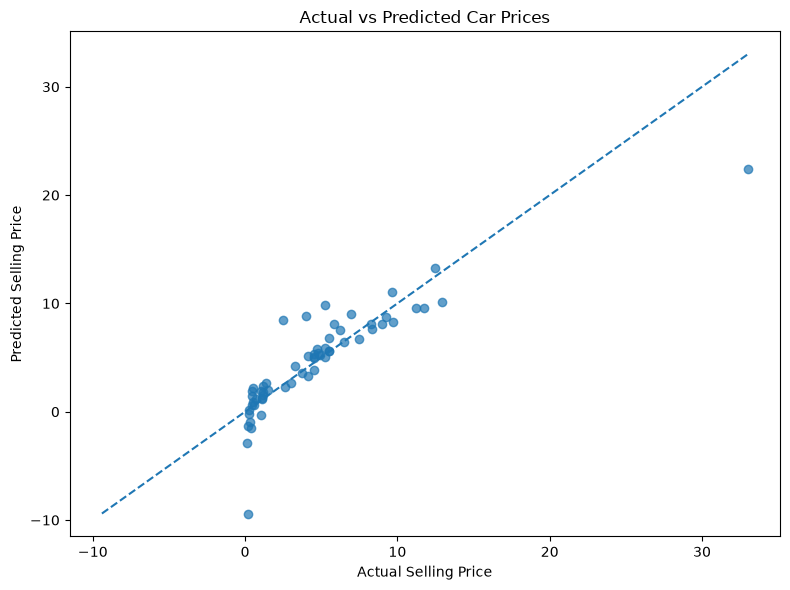

In [14]:
import matplotlib.pyplot as plt

FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_linear, alpha=0.7)

min_price = min(y_test.min(), y_pred_linear.min())
max_price = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()

plt.savefig(FIGURES_PATH / "actual_vs_predicted.png", dpi=300)
plt.show()